<a href="https://colab.research.google.com/github/TildeSkar/Applied-Deep-Learning---Physics---exrecises/blob/main/Exercise_05_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 5.1


In [286]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

**Simple Network**

We continue with the dataset first encountered in the previous exercise. Please refer to the discussion there for an introduction to the data and the learning objective.

Here, we manually implement a simple network architecture

In [287]:
# The code snippet below is responsible for downloading the dataset
# - for example when running via Google Colab.
#
# You can also directly download the file using the link if you work
# with a local setup (the !wget command will work either way assuming
# you are on a unix-based machine and have wget installed)
!wget -nc https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [288]:
import urllib.request

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

urllib.request.urlretrieve(url, "winequality-white.csv")

('winequality-white.csv', <http.client.HTTPMessage at 0x2ab7b914f10>)

In [289]:


# Before working with the data,
# we download and prepare all features

# load all examples from the file
data = np.genfromtxt("winequality-white.csv", delimiter=";", skip_header=1)

print(f"{data.shape = }")

# Prepare for proper training
rng = np.random.default_rng(1234)
rng.shuffle(data)  # randomly sort examples

# take the first 3000 examples for training
# (remember array slicing from last week)
X_train = data[:3000, :11]  # all features except last column
y_train = data[:3000, 11]  # quality column

# and the remaining examples for testing
X_test = data[3000:, :11]  # all features except last column
y_test = data[3000:, 11]  # quality column

print("First example:")
print("Features:", X_train[0])
print("Quality:", y_train[0])

data.shape = (4898, 12)
First example:
Features: [6.8000e+00 1.9000e-01 7.1000e-01 1.7500e+01 4.2000e-02 2.1000e+01
 1.1400e+02 9.9784e-01 2.8500e+00 5.0000e-01 9.5000e+00]
Quality: 6.0


# Problems

The goal is to implement the training of a neural network with one input layer, one hidden layer, and one output layer using gradient descent. We first (below) define the matrices and initialise with random values. We need W, b, W' and b'. The shapes will be:
  * W: (number of hidden nodes, number of inputs) named `W`
  * b: (number of hidden nodes) named `b`
  * W': (number of hidden nodes) named `Wp`
  * b': (one) named `bp`

Your tasks are:     
   * Implement a forward pass of the network as `dnn` (see below)
   * Implement a function that uses one data point to update the weights using gradient descent. You can follow the `update_weights` skeleton below
   * Now you can use the code below (training loop and evaluation) to train the network for multiple data points and even over several epochs. Try to find a set of hyperparameters (number of nodes in the hidden layer, learning rate, number of training epochs) that gives stable results. What is the best result (as measured by the loss on the training sample) you can get?

In [290]:
# Initialise weights with suitable random distributions
hidden_nodes = 20  # number of nodes in the hidden layer
n_inputs = 11  # input features in the dataset

W = rng.standard_normal(size=(hidden_nodes, 11)) * np.sqrt(2.0 / n_inputs)
b = rng.standard_normal(size=hidden_nodes) * np.sqrt(2.0 / n_inputs)
Wp = rng.standard_normal(size=hidden_nodes) * np.sqrt(2.0 / hidden_nodes)
bp = rng.standard_normal(size=(1))

print(f"{W.shape = }")

W.shape = (20, 11)


The ReLU activation function is defined as f(x)=max(0,x). If x is positive ReLU outputs x unchanged. If x is negative ReLU outputs 0. If x = 0 the ReLU will also output zero. This activation function is implemented below for our array x consisting of input features. 

In [291]:
# You can use this implementation of the ReLu activation function
def relu(x: np.ndarray) -> np.ndarray:
    """Simple implementation of a rectified linear unit.

    Parameters
    ----------
    x : array_like
        Array of input features.

    Returns
    -------
    np.ndarray
        Array containig function values of the relu for
        each element of the input array.
    """

    return np.maximum(x, 0)

Forward pass is the process where a neural network takes input data and passes it through its layers to poduce a prediction. It is how the network calculates its outputs using its current weights and biases. For our system with one hidden layer, each layer performs the following calculation as, 

$$z = Wx + b$$
We the apply our ReLU activation function $\sigma$ and obtain the output,

$$\hat{y}=\mathbf{W}^{\prime} \sigma(\mathbf{W} \vec{x}+\vec{b})+b^{\prime}$$

No activation is used on the output layer. 
This is implemented below

In [292]:
def dnn(
    x: np.ndarray,
    W: np.ndarray,
    b: np.ndarray,
    Wp: np.ndarray,
    bp: np.ndarray,
) -> np.ndarray:
    """Simple DNN.

    Parameters
    ----------
    x : array_like
        Array of input features.
    W : array_like
        Array of input layer weights.
    b : array_like
        Array of input layer biases.
    Wp : array__like
        Array of output layer weighs.
    bp : array_like
        Array of output layer biases

    Returns
    -------
    np.ndarray, shape (1,)
        Array containing the float output of the DNN.
    """

    y = Wp@ relu(W@x+b)+bp # Computes forward pass of the DNN using the input features, weights, and biases. The output is a single value representing the predicted quality of the wine.

    return y  # change to the calculated output

The backward pass instead calculate the gradients and determains how weights should change. It helps the network learn by calculation to improve those parameters. The backwards pass (backpropogation) the network learns from its mistakes. During the forward pass the network makes a prediction. During the backward pass it instead calculated how each weight and bias contributes to the prediction error. To do so the backward pass contains four main steps, 

1. Calculate the loss function: Meaning we compare the networks prediction with the correct answer. For the regression problem the objective function is the mean squared error between the prediction and the true label $y$:
$$
L=(\hat{y}-y)^{2}
$$

2. Calculate gradients: Next we calculate the gradients to determaine how much each weight and bias affects the loss. 

3. Propogate gradient backwards: We use the chain rule to calculate gradients thrpugh eaxh layer, starting from the output. 
Taking the partial derivatives - and diligently the applying chain rule - with respect to the different objects yields:

$$
\begin{aligned}
\frac{\partial L}{\partial b^{\prime}} &=2(\hat{y}-y) \\
\frac{\partial L}{\partial b_{k}} &=2(\hat{y}-y) \mathbf{W}_{k}^{\prime} \theta\left(\sum_{i} \mathbf{W}_{k i} x_{i}+b_{k}\right) \\
\frac{\partial L}{\partial \mathbf{W}_{k}^{\prime}} &=2(\hat{y}-y) \sigma\left(\sum_{i} \mathbf{W}_{k i} x_{i}+b_{k}\right) \\
\frac{\partial L}{\partial \mathbf{W}_{m k}} &=2(\hat{y}-y) \mathbf{W}_{m}^{\prime} \theta\left(\sum_{i} \mathbf{W}_{m i} x_{i}+b_{m}\right) x_{k}
\end{aligned}
$$

Here, $\Theta$ denotes the Heaviside step function.

4. Update the parameters: An optimizer the uses these gradients to update the weights and biases

NOTE: Heaviside H(z) function is 1 for z>1 and zero elsewhere. We choose H(0)=0. This must be specified in the function, as a second input. 

In [293]:
def update_weights(
    x: np.ndarray,
    y: np.ndarray,
    W: np.ndarray,
    b: np.ndarray,
    Wp: np.ndarray,
    bp: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Updates weights for given inputs, targets,
    weights, and biases.

    Parameters
    ----------
    x : array_like
        Array of input features.
    y : array_like
        Array of target features.
    W : array_like
        Array of input layer weights.
    b : array_like
        Array of input layer biases.
    Wp : array__like
        Array of output layer weighs.
    bp : array_like
        Array of output layer biases

    Returns
    -------
    tuple
        Tuple of updated weight and bias arrays.
    """

    learning_rate = 10**(-5) # A usually good starting point for the learning rate is 10^-5, but you can experiment with different values to see how it affects the training process.
    
    
    y_pre = dnn(x, W, b, Wp, bp) # computing the prediction of the network using forward pass


    # Computing the gradients for each of the weights and biases using the chain rule of differentiation
    bp_gradient = 2 * (y_pre - y) # gradient for output bias
    b_gradient = 2 * (y_pre - y) * Wp * np.heaviside(W @ x + b, 0) # gradient for output bias
    Wp_gradient = 2 * (y_pre - y) * relu(W @ x + b) # gradient for output weights
    W_gradient = np.outer(b_gradient, x) # gradient for input weights

    # Updating the weights and biases using the calculated gradients and the learning rate
    W_new = W - learning_rate * W_gradient
    b_new = b - learning_rate * b_gradient
    Wp_new = Wp - learning_rate * Wp_gradient
    bp_new = bp - learning_rate * bp_gradient


    return W_new, b_new, Wp_new, bp_new # return the new weights

# Training loop and evaluation below

In [294]:
# The code below implements the training.
# If you correctly implement  dnn and update_weights above,
# you should not need to change anything below.
# (apart from increasing the number of epochs)

train_losses = []
test_losses = []

# How many epochs to train
# This will just train for one epoch
# You will want a higher number once everything works
n_epochs = 19

# Loop over the epochs
for ep in range(n_epochs):
    # Each epoch is a complete over the training data
    for i in range(X_train.shape[0]):
        # pick one example
        x = X_train[i]
        y = y_train[i]

        # use it to update the weights
        W, b, Wp, bp = update_weights(x, y, W, b, Wp, bp)

    # Calculate predictions for the full training and testing sample
    y_pred_train = [dnn(x, W, b, Wp, bp)[0] for x in X_train]
    y_pred = [dnn(x, W, b, Wp, bp)[0] for x in X_test]

    # Calculate aver loss / example over the epoch
    train_loss = np.sum((y_pred_train - y_train) ** 2) / y_train.shape[0]
    test_loss = np.sum((y_pred - y_test) ** 2) / y_test.shape[0]

    # print some information
    print("Epoch:", ep, "Train Loss:", train_loss, "Test Loss:", test_loss)

    # and store the losses for later use
    train_losses.append(train_loss)
    test_losses.append(test_loss)

Epoch: 0 Train Loss: 0.9844986206514195 Test Loss: 1.0210630875412823
Epoch: 1 Train Loss: 0.7244015958945582 Test Loss: 0.7407786832719108
Epoch: 2 Train Loss: 0.6918463915392324 Test Loss: 0.709117049503314
Epoch: 3 Train Loss: 0.6810202152604892 Test Loss: 0.6955989147075435
Epoch: 4 Train Loss: 0.6735928953544337 Test Loss: 0.6874871858225543
Epoch: 5 Train Loss: 0.6679218874634395 Test Loss: 0.6819856253449053
Epoch: 6 Train Loss: 0.6625753333859892 Test Loss: 0.676675650074998
Epoch: 7 Train Loss: 0.6581465636053484 Test Loss: 0.6719171771651181
Epoch: 8 Train Loss: 0.6540811452349239 Test Loss: 0.6672368072771016
Epoch: 9 Train Loss: 0.6500846598133843 Test Loss: 0.6629358387351597
Epoch: 10 Train Loss: 0.6471975739811702 Test Loss: 0.659235445225507
Epoch: 11 Train Loss: 0.6449377032811922 Test Loss: 0.6560339628475401
Epoch: 12 Train Loss: 0.6427463785182465 Test Loss: 0.6533964369737151
Epoch: 13 Train Loss: 0.6405761953037736 Test Loss: 0.650443699418619
Epoch: 14 Train Loss

Best loss: 0.6371699969289081 Final loss: 0.6371699969289081
Correlation coefficient: 0.44515840914443117


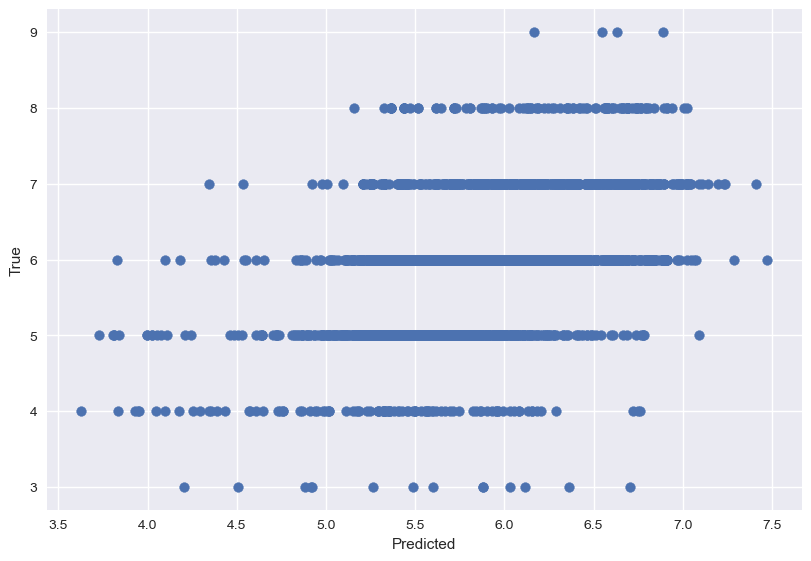

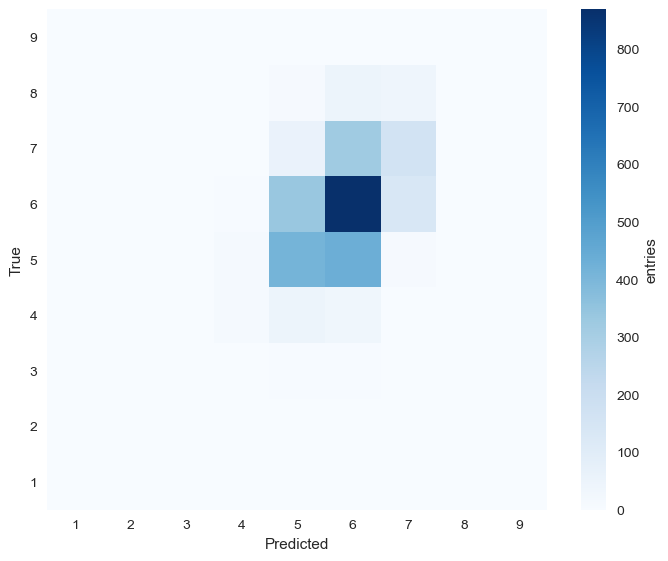

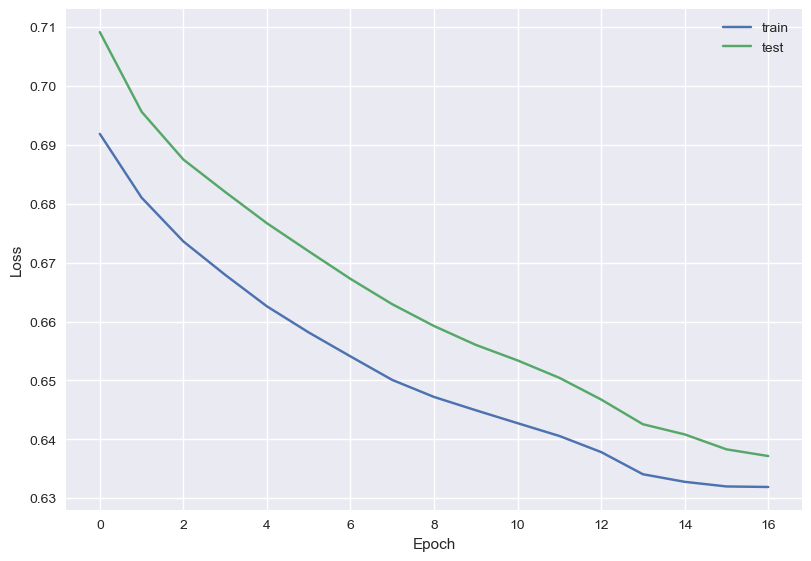

In [295]:
# After the training:

# Prepare scatter plot
y_pred = [dnn(x, W, b, Wp, bp)[0] for x in X_test]

print("Best loss:", min(test_losses), "Final loss:", test_losses[-1])

print("Correlation coefficient:", np.corrcoef(y_pred, y_test)[0, 1])
fig, ax = plt.subplots(layout="constrained")
ax.scatter(y_pred_train, y_train)
ax.set(
    xlabel="Predicted",
    ylabel="True",
)

fig, ax = plt.subplots(layout="constrained")
h = ax.hist2d(
    y_pred_train,
    y_train,
    bins=[np.arange(0.5, 10.5, 1), np.arange(0.5, 10.5, 1)],
    cmap="Blues",
)

ax.set(
    xlabel="Predicted",
    ylabel="True",
    aspect="equal",
)

cbar = fig.colorbar(h[3], ax=ax)
cbar.set_label("entries")


# Prepare and loss over time
fig, ax = plt.subplots(layout="constrained")
ax.plot(train_losses[2:], label="train")
ax.plot(
    test_losses[2:], label="test"
)  # we omit the first data points as the first loss is typically very high which makes it difficult to read the plot.
ax.legend()
ax.set(
    xlabel="Epoch",
    ylabel="Loss",
);

## Results
I started with nodes = 50, learning rate = 10^-5 and epochs = 45. The best train loss was obtained for Epoch: 20 Train Loss: 0.64911514683117 Test Loss: 0.617867206637848. After more epochs the training loss and test loss started increasing again. For  Epoch: 49 Train Loss: 0.694504300102422 Test Loss: 0.6511789572166029.

Next I tried varying the number of nodes.The smallest training loss was obtained for Epoch: 28 Train Loss: 0.6426961521769864 Test Loss: 0.6274926103699061. This was smaller than for 50 nodes but the test loss was higher. Epoch: 49 Train Loss: 0.6582719856816859 Test Loss: 0.6299974998396369 sowing that when run for more epochs test and train loss started increasing again. 

For 20 nodes we obtained the best training loss for Epoch: 18 Train Loss: 0.6319201543913975 Test Loss: 0.6371699969289081. But the test loss increased. For more epochs the train and test loss started icreasing again.  Epoch: 49 Train Loss: 0.6840504422023637 Test Loss: 0.6964769936636858


Decreasing the number of nodes appears to have improved training performance in these runs, but test performance became worse.This illustrates the difference between fitting the training data and generalizing to unseen data.


Next I tried increasing the number of nodes to 100. Then when trainging I let the epochs be 200. The ytaining loss and test loss keept decreasing for these values. Thus by running it even longer the accuracy could probably be increased even more. 
Epoch: 199 Train Loss: 0.6423120923495225 Test Loss: 0.6429895548432175

However as we saw above we obtain better losses for fewer nodes and less epochs. Thus these where more efficient while yielding similar reults. Traing for 200 epochs took 24.7 s which is quite alot for such a simple network. Thus expaninging the nodes and calculateing for more epoch does not seem like the most efficient choice. 


Next we investigate the affect of learning rate. 
For learningrate 10^-5 after 50 epochs we had Epoch: 49 Train Loss: 0.694504300102422 Test Loss: 0.6511789572166029. Showing signs of overfitting due to the increase of test and train loss. 

We let nodes = 50 and we runt it for 50 epochs. We increase the learing rate to 10^-4. 
Epoch: 49 Train Loss: 0.6633757018620285 Test Loss: 0.6364842310572392. The results imporved and overfitting was not as storngly observed in the grapth since the train and test loss did not increase in the same way. 

Next we increase learning rate t 10^-3. This showed to be to large and no appropiate soulution was found at all. Next I tried decreasing the learnng rate even further to 10^-6. I also increased epochs again to 200. This showed a very slow improvement of accuracy. Epoch: 199 Train Loss: 0.7278430216090671 Test Loss: 0.6811701638056779. A larger learning rate is thus better for faster computations. 


## Conclussions
From the experiments it was found that the smallest train loss was obtained for nodes= 20, learning rate 10^-5 and epochs=18 which had a train loss of 6319201543913975 Test Loss: 0.6371699969289081. These results show that a lower training loss does not necessarily correspond to better performance on unseen data. The best reported training loss was obtained using 20 hidden nodes, whereas the lowest corresponding test loss was obtained using 50 hidden nodes. Which after Epoch: 20 Train Loss: 0.64911514683117 Test Loss: 0.617867206637848. 

Training for more epoch showed to not always improve the results. For many cases both training and test loss started increasing when run for more epochs. In other cases the training loss kept decreasing however slowly when  run for epochs up to 200. Training for 200 epochs took approximately 24.7 seconds. Therefore, increasing the number of hidden nodes and epochs did not appear to be the most computationally efficient approach among the configurations tested.

It was found that larger learning rate allowed the network to make faster progress during training in this experiment. However, increasing the learning rate further to (10^{-3}) caused unstable training, and the network did not converge to a satisfactory solution. For smaller learning rates the traning loss kept decreasing stably for every epoch but the progress was slow and stagnated somewhat. A learning rate that is too small results in slow convergence, while a learning rate that is too large may cause instability.

The experiments demonstrate that increasing the number of hidden nodes or training epochs does not necessarily improve neural network performance. Smaller networks can sometimes achieve comparable or better results with lower computational cost. To improve accuracy of these results the experiments should be repeted with diffrent random seeds, to account for the randomness present in the network construction. 

# Hint 1

We want a network with one hidden layer. As activiation in the hidden layer $\sigma$ we apply element-wise ReLu, while no activation is used for the output layer. The forward pass of the network then reads:
$$\hat{y}=\mathbf{W}^{\prime} \sigma(\mathbf{W} \vec{x}+\vec{b})+b^{\prime}$$

# Hint 2

For the regression problem the objective function is the mean squared error between the prediction and the true label $y$:
$$
L=(\hat{y}-y)^{2}
$$

Taking the partial derivatives - and diligently the applying chain rule - with respect to the different objects yields:

$$
\begin{aligned}
\frac{\partial L}{\partial b^{\prime}} &=2(\hat{y}-y) \\
\frac{\partial L}{\partial b_{k}} &=2(\hat{y}-y) \mathbf{W}_{k}^{\prime} \theta\left(\sum_{i} \mathbf{W}_{k i} x_{i}+b_{k}\right) \\
\frac{\partial L}{\partial \mathbf{W}_{k}^{\prime}} &=2(\hat{y}-y) \sigma\left(\sum_{i} \mathbf{W}_{k i} x_{i}+b_{k}\right) \\
\frac{\partial L}{\partial \mathbf{W}_{m k}} &=2(\hat{y}-y) \mathbf{W}_{m}^{\prime} \theta\left(\sum_{i} \mathbf{W}_{m i} x_{i}+b_{m}\right) x_{k}
\end{aligned}
$$

Here, $\Theta$ denotes the Heaviside step function.